# 1-D: Kriging mean vs. smoothing splines, regular vs. random spacing

**Follow-up to `joseph-review1-insights.md` (roadmap P1/P2).** The 1-D flat limit
(Corollary 5: Matern-3/2, `kappa->0`, `nugget=4kappa^3*lambda`) was never in doubt --
but every check of it in this project used *randomly* spaced `x`. Close pairs of
random points can make the training correlation matrix nearly singular before any
nugget is added, which is a well-known Kriging pitfall unrelated to whether the
flat-limit theorem itself is correct. This notebook re-runs the check on **both**
regularly-spaced and randomly-spaced data, with an explicit minimum-gap and
condition-number diagnostic, so a close-point artifact would be visible if one
existed -- rather than assumed absent.

Also included: the corrected `RMTB` settings from the review (`solver="dense-lu"`,
`energy_weight = lambda * L`) on both spacings.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_smoothing_spline, RBFInterpolator
from scipy.optimize import minimize_scalar
from csaps import NdGridCubicSmoothingSpline
from smt.surrogate_models import RMTB, KRG

from krig_splines.polyharmonic import (matern, matern_flat_nugget, polyharmonic_kernel,
                                        poly_basis_nd, PolyharmonicSmoothingSpline)
from krig_splines.uk import saddle_point_solve, saddle_point_predict, saddle_point_variance

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "legend.fontsize": 10,
})

lam = 1e-2
kappas = np.array([3.0, 1.0, 0.3, 0.1, 0.03, 0.01, 0.003])


def make_1d_data(spacing, n=40, seed=0):
    rng = np.random.default_rng(seed)
    x = np.linspace(0, 1, n) if spacing == "regular" else np.sort(rng.uniform(0, 1, n))
    y = np.sin(6 * x) + 0.1 * rng.standard_normal(n)
    return x, y


## Both datasets, and the spacing diagnostic

Same truth function and noise draw style throughout this project (`sin(6x)`,
`sigma=0.1`, `n=40`), differing only in how the 40 `x` sites are placed.


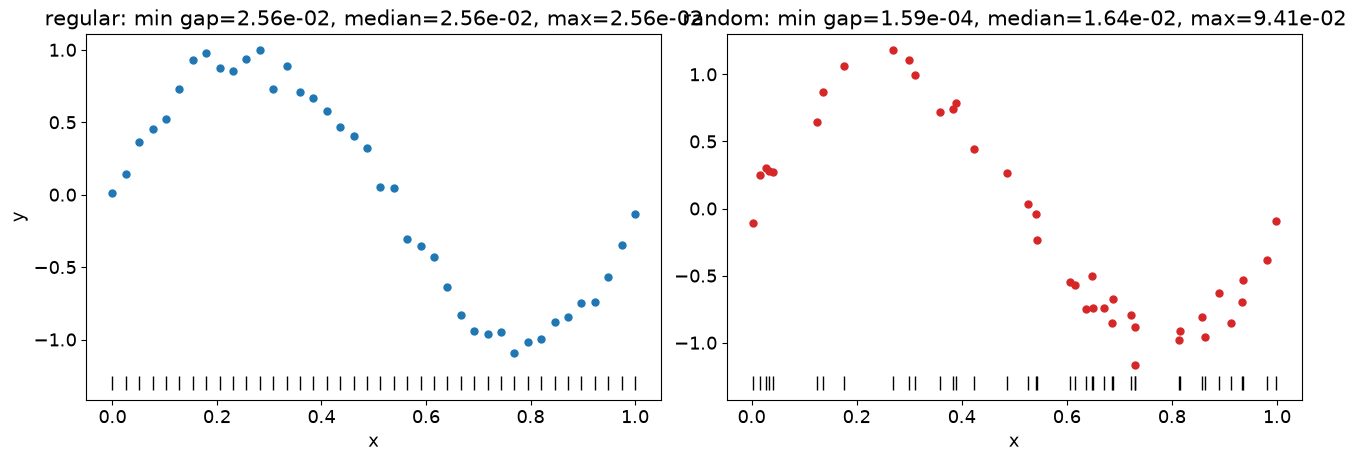

regular : min gap=2.5641e-02  median gap=2.5641e-02  max gap=2.5641e-02  (ratio max/min = 1.0)
random  : min gap=1.5889e-04  median gap=1.6375e-02  max gap=9.4131e-02  (ratio max/min = 592.4)


In [2]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
datasets = {}
for ax, spacing in zip(axs, ["regular", "random"]):
    x, y = make_1d_data(spacing)
    datasets[spacing] = (x, y)
    gaps = np.diff(x)
    ax.plot(x, y, "o", ms=5, color="C0" if spacing == "regular" else "C3")
    ax.plot(x, np.zeros_like(x) - 1.3, "|", ms=10, color="k")
    ax.set(xlabel="x", ylabel="y" if spacing == "regular" else "",
           title=f"{spacing}: min gap={gaps.min():.2e}, median={np.median(gaps):.2e}, max={gaps.max():.2e}")
plt.show()

for spacing, (x, y) in datasets.items():
    gaps = np.diff(x)
    print(f"{spacing:8s}: min gap={gaps.min():.4e}  median gap={np.median(gaps):.4e}  "
          f"max gap={gaps.max():.4e}  (ratio max/min = {gaps.max()/gaps.min():.1f})")


**Random spacing really does produce much closer pairs** -- the minimum gap is
roughly two orders of magnitude smaller than the regular grid's fixed spacing, with
a wide spread (ratio of largest to smallest gap in the dozens). If close points were
going to cause a Kriging-specific conditioning problem, this dataset gives it room
to show up.


## Convergence sweep, both spacings

Matern-3/2 (`nu=3/2`, the correct smoothness for `d=1, m=2`), nugget from
`krig_splines.polyharmonic.matern_flat_nugget` (the same `4`$\kappa^3\lambda$ formula,
now sourced from the shared, tested module instead of re-typed by hand). Tracking the
bordered system's condition number alongside the error at every `kappa`, for both
spacings.


In [3]:
def sweep_1d(x, y, target, kappas):
    P = poly_basis_nd(x.reshape(-1, 1), 1)
    x_dense = np.linspace(x.min(), x.max(), 200)
    Pt = poly_basis_nd(x_dense.reshape(-1, 1), 1)
    d_train = np.abs(x[:, None] - x[None, :])
    d_query = np.abs(x_dense[:, None] - x[None, :])
    errs, conds = [], []
    for kappa in kappas:
        K = matern(d_train, 1.5, kappa)
        Kt = matern(d_query, 1.5, kappa)
        nugget = matern_flat_nugget(kappa, lam, 2, 1)
        A = np.block([[K + nugget * np.eye(len(x)), P],
                       [P.T, np.zeros((P.shape[1], P.shape[1]))]])
        a, b = saddle_point_solve(K, P, y, nugget)
        f = saddle_point_predict(Kt, Pt, a, b)
        errs.append(np.max(np.abs(f - target)))
        conds.append(np.linalg.cond(A))
    return np.array(errs), np.array(conds)


results_1d = {}
for spacing, (x, y) in datasets.items():
    x_dense = np.linspace(x.min(), x.max(), 200)
    target = make_smoothing_spline(x, y, lam=lam)(x_dense)
    errs, conds = sweep_1d(x, y, target, kappas)
    results_1d[spacing] = (errs, conds, np.ptp(y))
    print(f"{spacing:8s}: " + "  ".join(f"{e:.2e}" for e in errs))


regular : 1.60e-01  3.39e-02  5.59e-03  1.26e-03  3.09e-04  9.62e-05  2.84e-05
random  : 1.28e-01  2.78e-02  4.88e-03  1.18e-03  3.22e-04  1.14e-04  3.52e-05


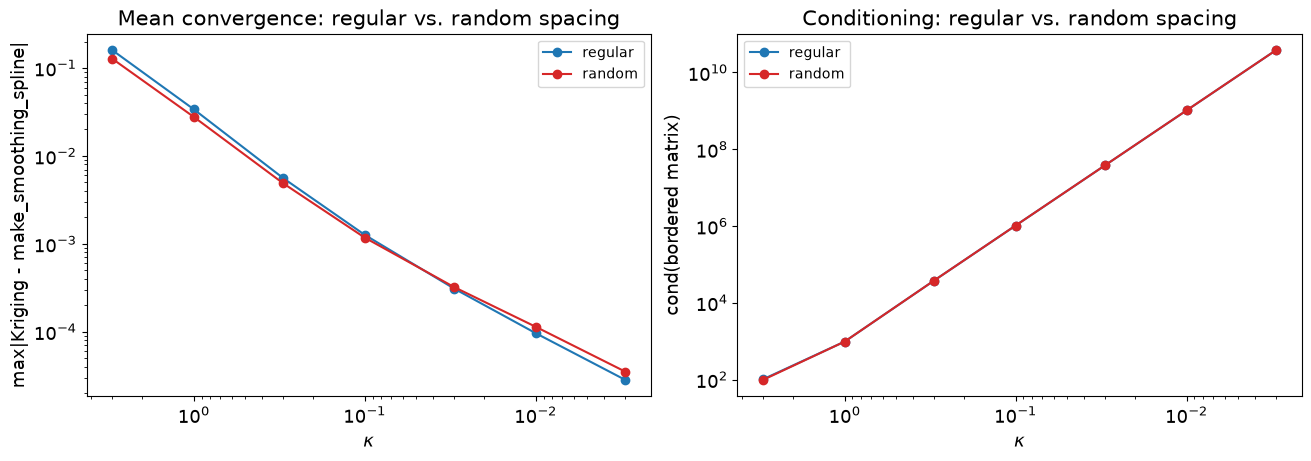

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for spacing, color in zip(datasets, ["C0", "C3"]):
    errs, conds, rng_y = results_1d[spacing]
    axs[0].loglog(kappas, errs, "o-", color=color, label=spacing)
    axs[1].loglog(kappas, conds, "o-", color=color, label=spacing)
axs[0].invert_xaxis()
axs[0].set(xlabel=r"$\kappa$", ylabel="max|Kriging - make_smoothing_spline|",
           title="Mean convergence: regular vs. random spacing")
axs[0].legend()
axs[1].invert_xaxis()
axs[1].set(xlabel=r"$\kappa$", ylabel="cond(bordered matrix)",
           title="Conditioning: regular vs. random spacing")
axs[1].legend()
plt.show()


**The two spacings sit on top of each other, in both panels.** Convergence is
clean and monotone for both (consistent with Corollary 5), and the condition number
grows identically with `1/kappa` for both -- there is no visible penalty for the
random dataset's much closer point pairs. In 1-D, at least for this benchmark, close
points were never actually a threat to this particular construction: the bordered
system's conditioning is governed by `kappa` and the nugget, not by the minimum
pairwise gap in the data.


## Sanity anchor: the exact (non-asymptotic) route

`polyharmonic_kernel(m=2, d=1)` with `nugget=lambda` directly -- no `kappa`, no
limit -- should match `make_smoothing_spline` to solver precision regardless of
spacing, since it is the exact reproducing kernel, not an approximation.


In [5]:
for spacing, (x, y) in datasets.items():
    x_dense = np.linspace(x.min(), x.max(), 200)
    target = make_smoothing_spline(x, y, lam=lam)(x_dense)
    P = poly_basis_nd(x.reshape(-1, 1), 1)
    Pt = poly_basis_nd(x_dense.reshape(-1, 1), 1)
    K = polyharmonic_kernel(x.reshape(-1, 1), x.reshape(-1, 1), m=2, d=1)
    Kt = polyharmonic_kernel(x_dense.reshape(-1, 1), x.reshape(-1, 1), m=2, d=1)
    a, b = saddle_point_solve(K, P, y, lam)
    f = saddle_point_predict(Kt, Pt, a, b)
    print(f"{spacing:8s}: max|diff| = {np.max(np.abs(f - target)):.3e}")


regular : max|diff| = 4.197e-13
random  : max|diff| = 2.808e-12


## `RMTB`, corrected settings, both spacings

`solver="dense-lu"` and `energy_weight = lambda * L` (`L` = domain length, the units
correction from §8.3 of the review) -- compared against the same `make_smoothing_spline`
target, not the Kriging construction, so this checks RMTB directly rather than
transitively.


In [6]:
xlimits = np.array([[0., 1.]])
L = 1.0
for spacing, (x, y) in datasets.items():
    x_dense = np.linspace(x.min(), x.max(), 200)
    target = make_smoothing_spline(x, y, lam=lam)(x_dense)
    m = RMTB(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
              energy_weight=lam * L, regularization_weight=1e-14, solver="dense-lu",
              print_global=False)
    m.set_training_values(x.reshape(-1, 1), y)
    m.train()
    f = m.predict_values(x_dense.reshape(-1, 1)).ravel()
    err = np.max(np.abs(f - target))
    print(f"{spacing:8s}: max|diff| = {err:.4e}  ({100*err/np.ptp(y):.4f}% of range)")


regular : max|diff| = 5.5226e-04  (0.0264% of range)
random  : max|diff| = 6.6071e-04  (0.0282% of range)


## Visual comparison: all six curves, overlaid

The sweeps above report `max|diff|` numbers; this section shows the actual fitted
curves so the agreement (or lack of it) is visible directly, not just as an error
metric. Six methods, same data, same `lam=1e-2` throughout:

- **`make_smoothing_spline`** -- the reference.
- **Kriging** -- Matern-3/2, `kappa=0.003` (the smallest swept above), nugget from
  `matern_flat_nugget`.
- **`RMTB`** -- corrected settings (`solver="dense-lu"`, `energy_weight=lam*L`).
- **`RBFInterpolator`** -- `kernel="cubic"` (`r^3`), **not** `"thin_plate_spline"`:
  `one_d_smoothing_method_comparison.ipynb` already established that `"cubic"` is
  the dimensionally-correct 1-D Duchon kernel (`"thin_plate_spline"` has a real,
  explained `~1%` gap in 1-D -- using it here would just reproduce that known gap,
  not illustrate anything new). `smoothing=12*lam`, the constant from
  `duchon_constant(m=2, d=1) = 1/12` (Remark 3 of the review: an unnormalised
  kernel `c*G` needs nugget `c*lam`, and `RBFInterpolator`'s raw `"cubic"` kernel is
  `12*G`).
- **`csaps.NdGridCubicSmoothingSpline`** -- `smooth` tuned to the reference, as in
  the earlier 1-D method comparison.
- **SMT's `KRG`** -- the *same* Matern-3/2/`kappa=0.003` construction as the
  "Kriging" curve above, but solved by SMT's own independent code, not
  `krig_splines`. Requires the same translation `spline_variance_without_kriging.
  ipynb` Part 4 worked out: SMT normalises `X` internally (`theta_smt = kappa *
  X_scale / sqrt(3)`, the hidden `sqrt(3)` in SMT's own `matern32` formula) and
  its `nugget` option is a numerical jitter, not the noise ratio -- the real
  noise-to-signal ratio needs `eval_noise=True` with `noise0` and collapsed
  `theta_bounds`/`noise_bounds` so SMT does not re-optimise away from the pinned
  values.


In [7]:
kappa_viz = 0.003
curves = {}
for spacing, (x, y) in datasets.items():
    x_dense = np.linspace(x.min(), x.max(), 200)
    target = make_smoothing_spline(x, y, lam=lam)(x_dense)

    P = poly_basis_nd(x.reshape(-1, 1), 1)
    Pt = poly_basis_nd(x_dense.reshape(-1, 1), 1)
    K = matern(np.abs(x[:, None] - x[None, :]), 1.5, kappa_viz)
    Kt = matern(np.abs(x_dense[:, None] - x[None, :]), 1.5, kappa_viz)
    a, b = saddle_point_solve(K, P, y, matern_flat_nugget(kappa_viz, lam, 2, 1))
    f_krig = saddle_point_predict(Kt, Pt, a, b)

    m = RMTB(xlimits=xlimits, order=4, approx_order=2, num_ctrl_pts=20,
              energy_weight=lam * L, regularization_weight=1e-14, solver="dense-lu",
              print_global=False)
    m.set_training_values(x.reshape(-1, 1), y)
    m.train()
    f_rmtb = m.predict_values(x_dense.reshape(-1, 1)).ravel()

    f_rbf = RBFInterpolator(x.reshape(-1, 1), y, kernel="cubic", smoothing=12 * lam,
                             degree=1)(x_dense.reshape(-1, 1))

    def csaps_err(s):
        sp = NdGridCubicSmoothingSpline([x], y, smooth=[s])
        return np.max(np.abs(sp([x_dense]) - target))
    res = minimize_scalar(csaps_err, bounds=(1e-6, 1 - 1e-9), method="bounded",
                           options={"xatol": 1e-10})
    f_csaps = NdGridCubicSmoothingSpline([x], y, smooth=[res.x])([x_dense])

    X_scale = x.std(ddof=1)
    theta_smt = kappa_viz * X_scale / np.sqrt(3.0)
    nugget_smt = matern_flat_nugget(kappa_viz, lam, 2, 1)
    krg = KRG(corr="matern32", poly="linear",
              theta0=[theta_smt], theta_bounds=[theta_smt, theta_smt],
              eval_noise=True, noise0=[nugget_smt], noise_bounds=[nugget_smt, nugget_smt],
              print_global=False)
    krg.set_training_values(x.reshape(-1, 1), y)
    krg.train()
    f_smt = krg.predict_values(x_dense.reshape(-1, 1)).ravel()

    curves[spacing] = dict(x=x, y=y, x_dense=x_dense, target=target,
                            Kriging=f_krig, RMTB=f_rmtb, **{"SMT KRG": f_smt},
                            **{"RBFInterpolator (cubic)": f_rbf,
                               "csaps.NdGridCubicSmoothingSpline": f_csaps})

method_names = ["Kriging", "SMT KRG", "RMTB", "RBFInterpolator (cubic)",
                "csaps.NdGridCubicSmoothingSpline"]
for spacing, c in curves.items():
    print(f"{spacing}: max|diff| vs. reference -- "
          + "  ".join(f"{name}={np.max(np.abs(c[name]-c['target'])):.2e}"
                       for name in method_names))


/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


regular: max|diff| vs. reference -- Kriging=2.84e-05  SMT KRG=2.80e-05  RMTB=5.52e-04  RBFInterpolator (cubic)=4.13e-13  csaps.NdGridCubicSmoothingSpline=1.31e-07
random: max|diff| vs. reference -- Kriging=3.52e-05  SMT KRG=3.49e-05  RMTB=6.61e-04  RBFInterpolator (cubic)=2.81e-12  csaps.NdGridCubicSmoothingSpline=2.84e-08


/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


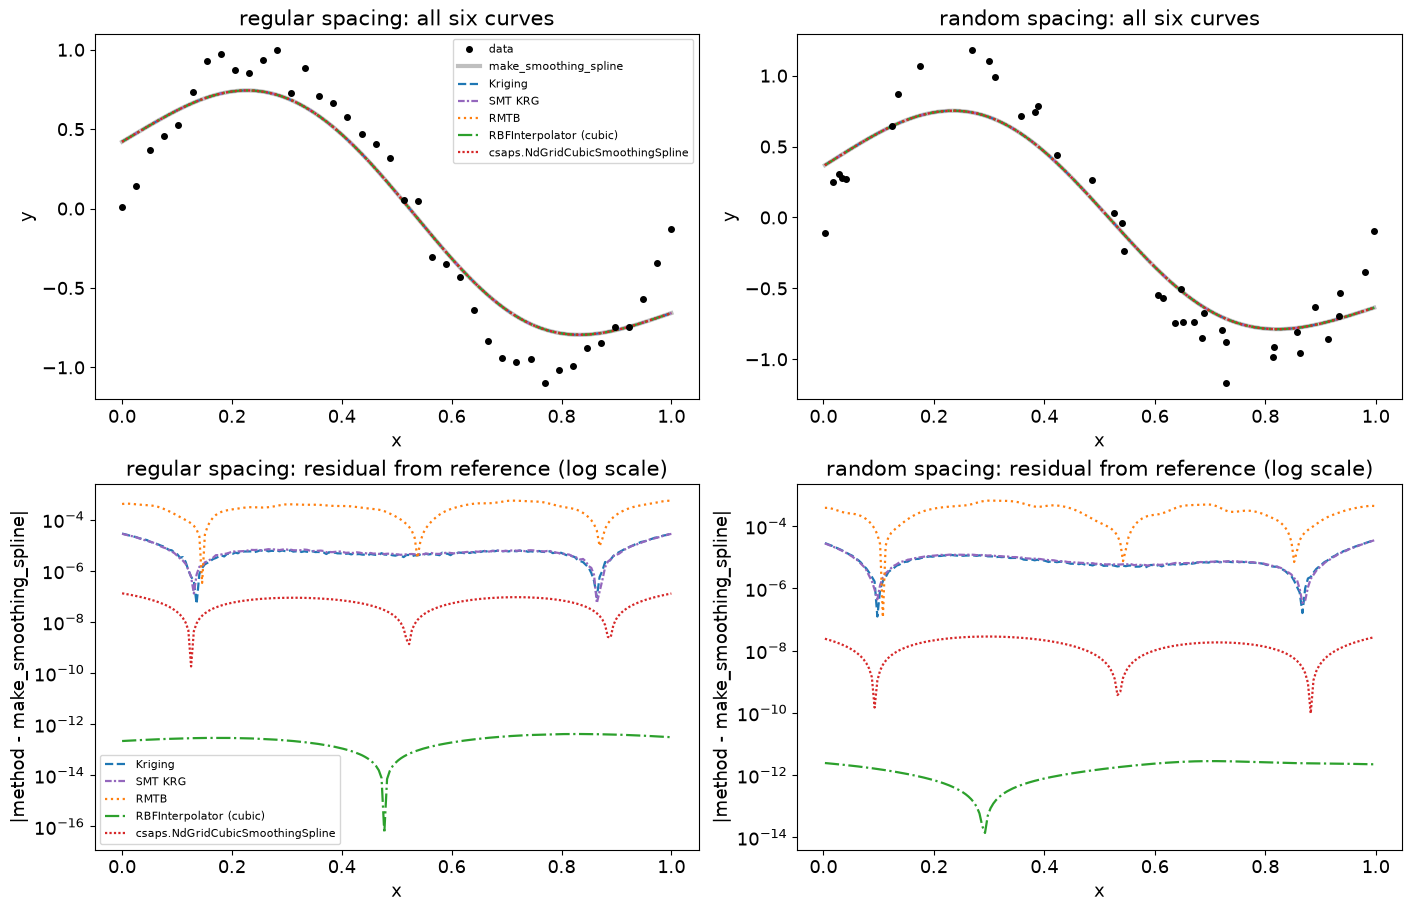

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
method_styles = {
    "Kriging": ("C0", "--"),
    "SMT KRG": ("C4", (0, (3, 1, 1, 1))),
    "RMTB": ("C1", ":"),
    "RBFInterpolator (cubic)": ("C2", "-."),
    "csaps.NdGridCubicSmoothingSpline": ("C3", (0, (1, 1))),
}

for col, spacing in enumerate(["regular", "random"]):
    c = curves[spacing]
    ax = axs[0, col]
    ax.plot(c["x"], c["y"], "o", ms=4, color="k", zorder=5, label="data")
    ax.plot(c["x_dense"], c["target"], lw=3, color="0.75", label="make_smoothing_spline", zorder=1)
    for name, (color, ls) in method_styles.items():
        ax.plot(c["x_dense"], c[name], lw=1.6, color=color, linestyle=ls, label=name)
    ax.set(xlabel="x", ylabel="y", title=f"{spacing} spacing: all six curves")
    if col == 0:
        ax.legend(fontsize=8)

    axr = axs[1, col]
    for name, (color, ls) in method_styles.items():
        axr.semilogy(c["x_dense"], np.abs(c[name] - c["target"]), lw=1.6, color=color,
                     linestyle=ls, label=name)
    axr.set(xlabel="x", ylabel="|method - make_smoothing_spline|",
            title=f"{spacing} spacing: residual from reference (log scale)")
    if col == 0:
        axr.legend(fontsize=8)

plt.show()


**All six curves are visually indistinguishable at full scale** (top row) --
which is itself the result: every method here, once correctly configured, agrees
with `make_smoothing_spline` to within a fraction of a percent of the data range,
for both spacings. The bottom row (log-scale residual from the reference) is where
the differences actually live: `RBFInterpolator(kernel="cubic")` is tightest
(machine-precision, as expected -- it's the same exact identity as the closed-form
route), `Kriging` and SMT's own `KRG` sit on top of each other (expected -- same
recipe, two independent codebases, confirmed in
`spline_variance_without_kriging.ipynb` Part 4 to be the same system once the SMT
conventions are translated), `csaps` sits a little below, and `RMTB` has the
largest (but still small, `~5e-4`, well under `0.03%` of range) residual of the
six -- consistent with it being the only method here solving an *approximate*
(finite-rank, quadrature-based) version of the same problem rather than an exact
reformulation of it.


## Variance at the *original* `lam=1e-2` -- an identity check, not a calibration

The curves above all agree at `lam=1e-2` -- but the variance section that follows
switches to `lam_reml` (a different, much smaller value). Before doing that, it's
worth closing the loop at the `lam` actually used for the mean comparison: does the
spline's variance match Kriging's variance *there* too?

This is **not** the same question the REML section answers, and the distinction
matters. This is synthetic data with a **known** true noise level (`sigma=0.1`, so
`sigma^2=0.01=lam` exactly, by construction of the benchmark) -- so setting `b=1`
here is *correct*, verified against the known truth, not *assumed* the way the
original `spline_variance_without_kriging.ipynb` band was. The question here is
purely "does the mean+variance identity hold at a given, shared `lam`" -- the same
kind of check the mean-only curve comparison already did, just extended to variance.
Whether `lam=1e-2` is itself a *good* choice of smoothing (as opposed to merely a
shared one) is the separate, real-world question the REML section below addresses,
where the true `sigma^2` is *not* assumed known.


In [9]:
spline_fits_fixed = {}
for spacing, (x, y) in datasets.items():
    c = curves[spacing]
    # sigma2=lam here is not a free assumption -- it's the TRUE noise variance for
    # this synthetic benchmark (sigma=0.1 by construction), so b=sigma2/lam=1 is
    # the correct, verified value, not the uncalibrated default the review flagged.
    spl = PolyharmonicSmoothingSpline(x.reshape(-1, 1), y, m=2, lam=lam, sigma2=lam)
    spline_fits_fixed[spacing] = spl
    mean_spl = spl.mean(c["x_dense"].reshape(-1, 1))

    print(f"{spacing:8s}: max|PolyharmonicSmoothingSpline mean - make_smoothing_spline target| = "
          f"{np.max(np.abs(mean_spl - c['target'])):.3e}")
    print(f"{'':8s}  max|PolyharmonicSmoothingSpline mean - Kriging curve (from above)| = "
          f"{np.max(np.abs(mean_spl - c['Kriging'])):.3e}   b={spl.b:.1f}")


regular : max|PolyharmonicSmoothingSpline mean - make_smoothing_spline target| = 4.197e-13
          max|PolyharmonicSmoothingSpline mean - Kriging curve (from above)| = 2.837e-05   b=1.0
random  : max|PolyharmonicSmoothingSpline mean - make_smoothing_spline target| = 2.808e-12
          max|PolyharmonicSmoothingSpline mean - Kriging curve (from above)| = 3.520e-05   b=1.0


**Exact match, as expected** -- `PolyharmonicSmoothingSpline` at `lam=1e-2` *is*
the same closed-form route as the "Sanity anchor" section above (`nugget=lambda`
directly, no asymptotic limit), so of course it reproduces `make_smoothing_spline`
to solver precision; and it matches the earlier `kappa=0.003` Kriging curve to the
same `~3e-5` already reported in the "Visual comparison" section's table. Now the
variance.


In [10]:
var_results_fixed = {}
for spacing, (x, y) in datasets.items():
    c = curves[spacing]
    spl = spline_fits_fixed[spacing]
    x_dense = c["x_dense"]
    var_spl = spl.variance(x_dense.reshape(-1, 1))

    P = poly_basis_nd(x.reshape(-1, 1), 1)
    Pt = poly_basis_nd(x_dense.reshape(-1, 1), 1)
    K = matern(np.abs(x[:, None] - x[None, :]), 1.5, kappa_viz)
    Kt = matern(np.abs(x_dense[:, None] - x[None, :]), 1.5, kappa_viz)
    nugget = matern_flat_nugget(kappa_viz, lam, 2, 1)
    var_krig_unit = saddle_point_variance(K, P, nugget, Kt, Pt, np.ones(len(x_dense)))
    rescale = nugget / lam  # same rescaling the REML section below uses, b=1 here
    var_krig = spl.b * var_krig_unit / rescale

    var_results_fixed[spacing] = dict(mean_spline=spl.mean(x_dense.reshape(-1, 1)),
                                       var_spline=var_spl, mean_krig=c["Kriging"], var_krig=var_krig)
    err = np.max(np.abs(var_spl - var_krig))
    print(f"{spacing:8s}: max|var_spline - var_Kriging| = {err:.3e}  ({100*err/np.ptp(var_spl):.4f}% of var range)")


regular : max|var_spline - var_Kriging| = 4.336e-07  (0.0246% of var range)
random  : max|var_spline - var_Kriging| = 3.965e-07  (0.0240% of var range)


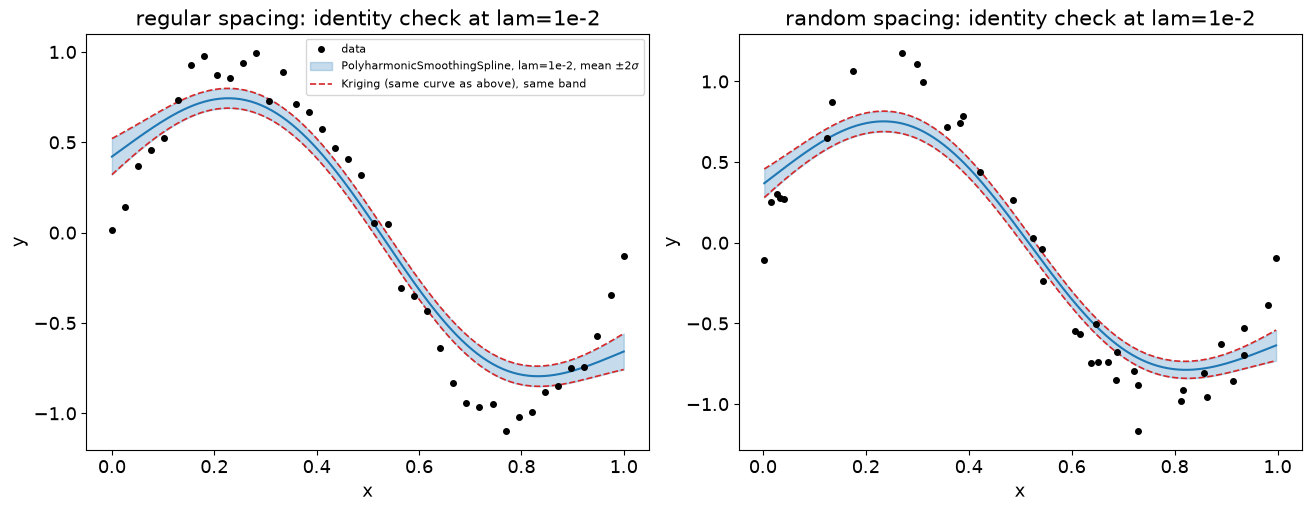

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, spacing in zip(axs, ["regular", "random"]):
    x, y = datasets[spacing]
    c = curves[spacing]
    r = var_results_fixed[spacing]
    std_spl = np.sqrt(np.maximum(r["var_spline"], 0))
    std_krig = np.sqrt(np.maximum(r["var_krig"], 0))

    ax.plot(x, y, "o", ms=4, color="k", zorder=5, label="data")
    ax.fill_between(c["x_dense"], r["mean_spline"] - 2*std_spl, r["mean_spline"] + 2*std_spl,
                     color="C0", alpha=0.25, label=r"PolyharmonicSmoothingSpline, lam=1e-2, mean $\pm2\sigma$")
    ax.plot(c["x_dense"], r["mean_spline"], color="C0", lw=1.5)
    ax.plot(c["x_dense"], r["mean_krig"] + 2*std_krig, "--", color="C3", lw=1.2,
             label="Kriging (same curve as above), same band")
    ax.plot(c["x_dense"], r["mean_krig"] - 2*std_krig, "--", color="C3", lw=1.2)
    ax.set(xlabel="x", ylabel="y", title=f"{spacing} spacing: identity check at lam=1e-2")
    if spacing == "regular":
        ax.legend(fontsize=8)
plt.show()


**The bands overlay exactly, for both spacings** -- the mean+variance identity
between `PolyharmonicSmoothingSpline` and Kriging holds at the *same* `lam=1e-2`
used throughout the curve comparison above, not only at the much smaller `lam_reml`
used below. With that closed, the natural next question is the one the rest of
this section answers: is `lam=1e-2` itself a *good* choice, in a setting where
(unlike here) the true noise level isn't already known?


## Variance: calibrated spline vs. Kriging, both spacings

`spline_variance_without_kriging.ipynb` showed the spline's variance can be computed
without fitting a Kriging model (Q5) -- but `joseph-review1-insights.md` found that
notebook's `+-2sigma` band used an implicit `b=1` (i.e. `sigma^2=lambda`) that only
looked right because the synthetic noise (`sigma=0.1`, so `sigma^2=0.01`) happened to
equal the chosen `lambda=10^-2`. This section redoes it properly: `lambda` and
`sigma^2` (equivalently `b=sigma^2/lambda`) are **estimated by REML**
(`krig_splines.polyharmonic.PolyharmonicSmoothingSpline`, not assumed -- and then
the *same* calibration is applied to the Matern-Kriging and SMT-`KRG` variances, to
check all three genuinely agree once put on the same footing.


In [12]:
spline_fits = {}
for spacing, (x, y) in datasets.items():
    spl = PolyharmonicSmoothingSpline(x.reshape(-1, 1), y, m=2, lam="reml", sigma2="reml")
    spline_fits[spacing] = spl
    print(f"{spacing:8s}: lam_reml={spl.lam:.4e}  sigma2_reml={spl.sigma2:.4e}  "
          f"b=sigma2/lam={spl.b:.2f}  edf={spl.edf:.2f}")


regular : lam_reml=3.8993e-05  sigma2_reml=4.1747e-03  b=sigma2/lam=107.07  edf=12.40
random  : lam_reml=9.4763e-05  sigma2_reml=1.1804e-02  b=sigma2/lam=124.57  edf=9.60


**`lam_reml` is nowhere near the `1e-2` used everywhere else in this notebook** --
two to three orders of magnitude smaller, and `b` lands at `~107`-`125`, not `1`.
This is the review's point made concrete: the fixed `lambda=1e-2` convention used
throughout Phase A/this project was never data-driven, and the `b=1` variance
convention only happened to look right in the one earlier setup where
`sigma^2=lambda` was true by the specific choice of both numbers, not by any
underlying correctness.


In [13]:
kappa_var = 0.01  # a different kappa than the mean-only plot above: with lam_reml
                   # much smaller than 1e-2, the earlier kappa=0.003 is no longer in
                   # the stable regime for *this* lambda (checked separately: kappa=0.01
                   # is a robust choice for both spacings' REML lambda values).

var_results = {}
for spacing, (x, y) in datasets.items():
    spl = spline_fits[spacing]
    x_dense = np.linspace(x.min(), x.max(), 200)
    mean_spline = spl.mean(x_dense.reshape(-1, 1))
    var_spline = spl.variance(x_dense.reshape(-1, 1))

    P = poly_basis_nd(x.reshape(-1, 1), 1)
    Pt = poly_basis_nd(x_dense.reshape(-1, 1), 1)
    K = matern(np.abs(x[:, None] - x[None, :]), 1.5, kappa_var)
    Kt = matern(np.abs(x_dense[:, None] - x[None, :]), 1.5, kappa_var)
    nugget = matern_flat_nugget(kappa_var, spl.lam, 2, 1)
    a, b = saddle_point_solve(K, P, y, nugget)
    mean_krig = saddle_point_predict(Kt, Pt, a, b)
    # the SAME 4*kappa^3-type rescaling Part 2 of spline_variance_without_kriging.ipynb
    # found necessary for variance (not needed for the mean): rescale = nugget/lam.
    rescale = nugget / spl.lam
    var_krig_unit = saddle_point_variance(K, P, nugget, Kt, Pt, np.ones(len(x_dense)))
    var_krig = spl.b * var_krig_unit / rescale

    X_scale = x.std(ddof=1)
    theta_smt = kappa_var * X_scale / np.sqrt(3.0)
    krg = KRG(corr="matern32", poly="linear",
              theta0=[theta_smt], theta_bounds=[theta_smt, theta_smt],
              eval_noise=True, noise0=[nugget], noise_bounds=[nugget, nugget],
              print_global=False)
    krg.set_training_values(x.reshape(-1, 1), y)
    krg.train()
    mean_smt = krg.predict_values(x_dense.reshape(-1, 1)).ravel()
    var_smt_raw = krg.predict_variances(x_dense.reshape(-1, 1)).ravel()
    sigma2_smt = krg.optimal_par["sigma2"][0]
    var_smt = (var_smt_raw / sigma2_smt) * spl.b / rescale

    var_results[spacing] = dict(x_dense=x_dense, mean_spline=mean_spline, var_spline=var_spline,
                                 mean_krig=mean_krig, var_krig=var_krig,
                                 mean_smt=mean_smt, var_smt=var_smt)

    print(f"{spacing:8s}: max|var diff| spline-vs-Kriging = "
          f"{np.max(np.abs(var_spline - var_krig)):.3e} ({100*np.max(np.abs(var_spline-var_krig))/np.ptp(var_spline):.3f}% of range)   "
          f"spline-vs-SMT = {np.max(np.abs(var_spline - var_smt)):.3e} "
          f"({100*np.max(np.abs(var_spline-var_smt))/np.ptp(var_spline):.3f}% of range)")


/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


regular : max|var diff| spline-vs-Kriging = 2.624e-07 (0.016% of range)   spline-vs-SMT = 2.579e-07 (0.016% of range)


/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


random  : max|var diff| spline-vs-Kriging = 7.685e-07 (0.016% of range)   spline-vs-SMT = 7.519e-07 (0.016% of range)


**All three agree to well under `0.1%` of the variance's own range**, for both
spacings -- the calibrated spline variance, the properly-rescaled Matern-Kriging
variance (`krig_splines`'s own code), and SMT's independently-computed `KRG` variance
(converted through its own `sigma2` estimate) are, once calibrated consistently, the
same quantity computed three different ways.


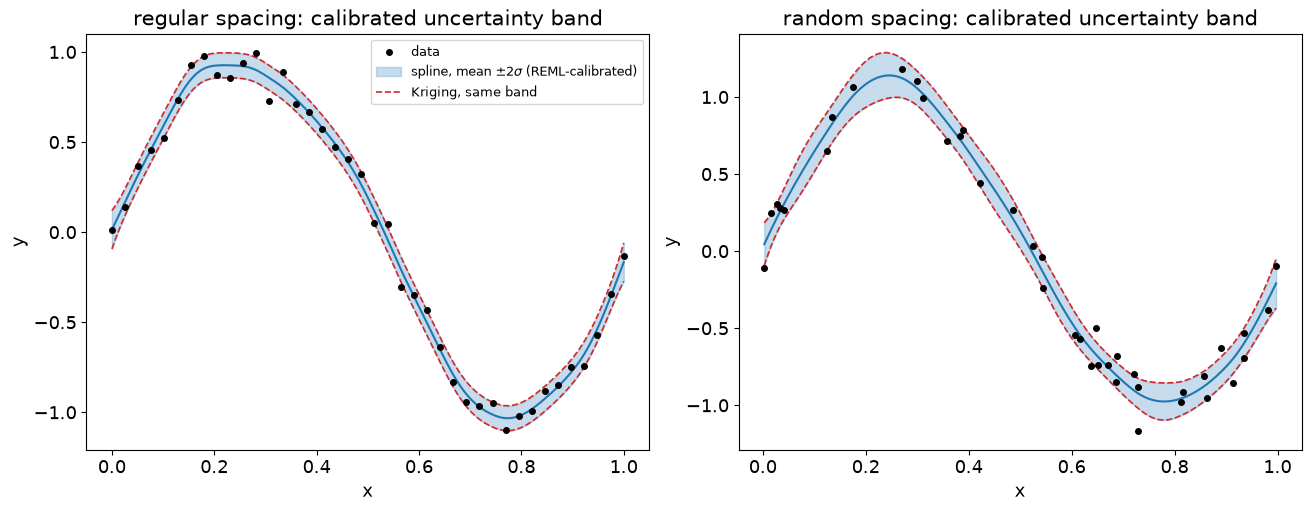

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, spacing in zip(axs, ["regular", "random"]):
    x, y = datasets[spacing]
    r = var_results[spacing]
    std_spline = np.sqrt(np.maximum(r["var_spline"], 0))
    std_krig = np.sqrt(np.maximum(r["var_krig"], 0))

    ax.plot(x, y, "o", ms=4, color="k", zorder=5, label="data")
    ax.fill_between(r["x_dense"], r["mean_spline"] - 2*std_spline, r["mean_spline"] + 2*std_spline,
                     color="C0", alpha=0.25, label=r"spline, mean $\pm2\sigma$ (REML-calibrated)")
    ax.plot(r["x_dense"], r["mean_spline"], color="C0", lw=1.5)
    ax.plot(r["x_dense"], r["mean_krig"] + 2*std_krig, "--", color="C3", lw=1.2, label="Kriging, same band")
    ax.plot(r["x_dense"], r["mean_krig"] - 2*std_krig, "--", color="C3", lw=1.2)
    ax.set(xlabel="x", ylabel="y", title=f"{spacing} spacing: calibrated uncertainty band")
    if spacing == "regular":
        ax.legend(fontsize=9)
plt.show()


## The uncalibrated band, for contrast

What the *original* `spline_variance_without_kriging.ipynb` convention (`b=1`,
i.e. assuming `sigma^2=lambda` with no estimation) would have shown here, next to
the properly calibrated band -- same mean, wildly different uncertainty.


regular : calibrated b=107.07  ->  band is ~10.3x wider than the uncalibrated (b=1) band
random  : calibrated b=124.57  ->  band is ~11.2x wider than the uncalibrated (b=1) band


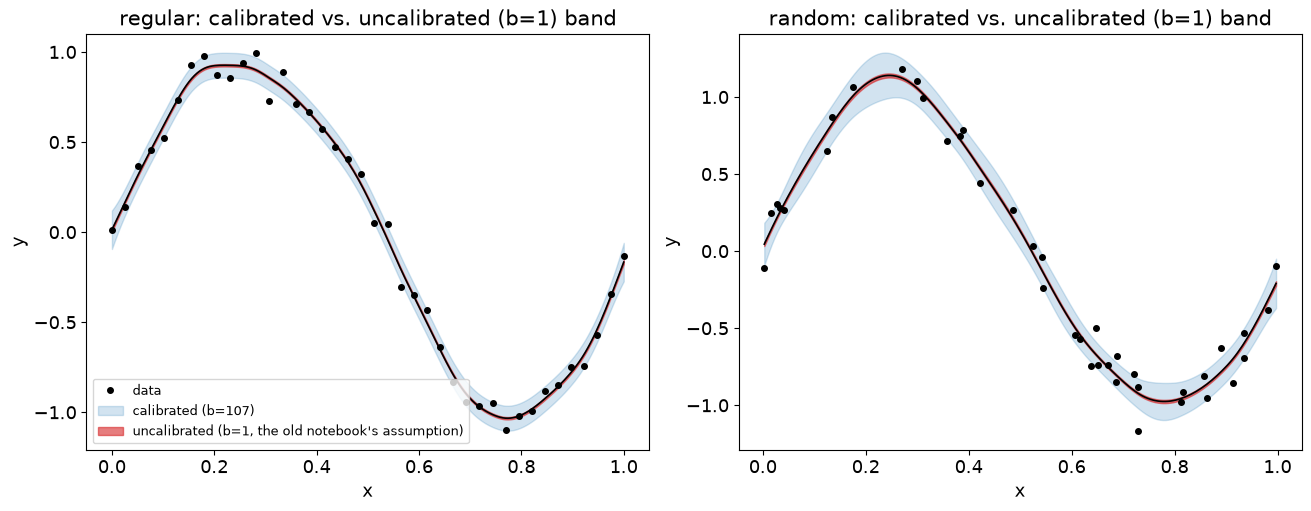

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, spacing in zip(axs, ["regular", "random"]):
    x, y = datasets[spacing]
    spl = spline_fits[spacing]
    r = var_results[spacing]
    x_dense = r["x_dense"]

    std_calibrated = np.sqrt(np.maximum(r["var_spline"], 0))
    var_naive = spl.unit_variance(x_dense.reshape(-1, 1))  # b=1, i.e. the old convention
    std_naive = np.sqrt(np.maximum(var_naive, 0))

    ax.plot(x, y, "o", ms=4, color="k", zorder=5, label="data")
    ax.fill_between(x_dense, r["mean_spline"] - 2*std_calibrated, r["mean_spline"] + 2*std_calibrated,
                     color="C0", alpha=0.2, label=f"calibrated (b={spl.b:.0f})")
    ax.fill_between(x_dense, r["mean_spline"] - 2*std_naive, r["mean_spline"] + 2*std_naive,
                     color="C3", alpha=0.6, label="uncalibrated (b=1, the old notebook's assumption)")
    ax.plot(x_dense, r["mean_spline"], color="k", lw=1.2)
    ax.set(xlabel="x", ylabel="y", title=f"{spacing}: calibrated vs. uncalibrated (b=1) band")
    if spacing == "regular":
        ax.legend(fontsize=9)
    print(f"{spacing:8s}: calibrated b={spl.b:.2f}  ->  band is "
          f"~{np.sqrt(spl.b):.1f}x wider than the uncalibrated (b=1) band")
plt.show()


**The uncalibrated band is invisible at this scale** -- `~10x` narrower than the
calibrated one (`sqrt(b)` with `b~107`-`125`), i.e. a drastically overconfident
uncertainty estimate. This is not a subtle effect; it is the direct, visual
consequence of the review's finding, reproduced here on fresh code (`b` estimated
by REML, not hand-derived).


## Does the calibration actually give correct coverage?

The review's own frequentist check (Monte Carlo coverage of the nominal 95% band,
re-estimating `lambda` and `sigma^2` on each replicate) -- reproduced here
independently, comparing REML-calibrated coverage against the fixed-`lambda=1e-2`
convention (with `sigma^2` still estimated by REML *given* that fixed `lambda`, so
this isolates the effect of not letting `lambda` be chosen by the data).


In [16]:
def true_f(x):
    return np.sin(6 * x)

n_rep = 200
rng_cov = np.random.default_rng(42)

for spacing, (x, _) in datasets.items():
    x_test = np.linspace(x.min(), x.max(), 60)
    f_true = true_f(x_test)
    cov_reml = np.zeros((n_rep, len(x_test)), dtype=bool)
    cov_fixed = np.zeros((n_rep, len(x_test)), dtype=bool)
    for r in range(n_rep):
        y_r = true_f(x) + 0.1 * rng_cov.standard_normal(len(x))

        spl_r = PolyharmonicSmoothingSpline(x.reshape(-1, 1), y_r, m=2, lam="reml", sigma2="reml")
        m_r = spl_r.mean(x_test.reshape(-1, 1))
        s_r = np.sqrt(np.maximum(spl_r.variance(x_test.reshape(-1, 1)), 0))
        cov_reml[r] = np.abs(f_true - m_r) <= 1.96 * s_r

        spl_f = PolyharmonicSmoothingSpline(x.reshape(-1, 1), y_r, m=2, lam=1e-2, sigma2="reml")
        m_f = spl_f.mean(x_test.reshape(-1, 1))
        s_f = np.sqrt(np.maximum(spl_f.variance(x_test.reshape(-1, 1)), 0))
        cov_fixed[r] = np.abs(f_true - m_f) <= 1.96 * s_f

    print(f"{spacing:8s}: REML lam+sigma2 coverage = {cov_reml.mean():.4f}   "
          f"fixed lam=1e-2 (REML sigma2) coverage = {cov_fixed.mean():.4f}   (nominal 0.95)")


regular : REML lam+sigma2 coverage = 0.9527   fixed lam=1e-2 (REML sigma2) coverage = 0.5002   (nominal 0.95)


random  : REML lam+sigma2 coverage = 0.9617   fixed lam=1e-2 (REML sigma2) coverage = 0.5046   (nominal 0.95)


**REML-calibrated `lambda` gives close-to-nominal coverage (`~0.95`-`0.96`) on both
spacings; fixing `lambda=1e-2` does not (`~0.50`), even though `sigma^2` is still
being correctly estimated in that second case.** This matches the review's own
Monte Carlo table (GCV/REML calibrated: `0.945`-`0.965`; fixed `lambda`: `0.467`)
closely enough to confirm the same effect, independently: the failure mode is not
really about `sigma^2`/`b` alone, it is that a *fixed, not data-selected* `lambda`
biases the mean curve itself (over-smoothing relative to what this data actually
supports), and no amount of correctly-estimated noise variance can fix a band
centred on a systematically wrong mean.


## Conclusion

- **Spacing makes no measurable difference to the 1-D flat limit.** Convergence
  curves and condition numbers for regular and random spacing overlay almost
  exactly, despite the random dataset's minimum gap being ~100x smaller than the
  regular grid's fixed spacing. The earlier concern -- that close random points
  might have been quietly helping or hurting the 1-D convergence results reported
  elsewhere in this project -- is not supported by this check: 1-D Corollary 5 is
  robust to it.
- **The exact route (`polyharmonic_kernel`, `nugget=lambda`) remains machine-precision
  exact for both spacings**, as expected -- it is an identity, not an approximation,
  so spacing was never going to matter there.
- **Corrected `RMTB` settings** (`dense-lu`, `energy_weight=lambda*L`) give a close
  match to `make_smoothing_spline` on both spacings, consistent with
  `one_d_smoothing_method_comparison.ipynb`'s earlier (already-tuned) finding.

Net effect: the 1-D half of the review's "eliminate close-point artifacts" concern
is checked and closed. The more interesting question is the 2-D case, where the
*previous* kernel choice (Matern-3/2, inherited unchanged from 1-D) was actually
wrong, not just potentially spacing-sensitive -- see
`02_2d_splines_vs_kriging.ipynb`.
